In [1]:
import cv2
import numpy as np
import os
from data_utils import load_images, make_dataset

I0000 00:00:1792062092.806289   74446 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792062092.806828   74446 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792062093.072893   74446 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792062095.013943   74446 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Reusable tf.data pipeline with caching and prefetching: decoding happens once, then the data is cached in memory and prefetched while the model trains.

In [2]:
train_ds, val_ds, classes = make_dataset("../Data/raw", batch_size=32, val_split=0.2, seed=42)
for images, labels in train_ds.take(1):
    print(images.shape, images.dtype, labels.shape)
import tensorflow as tf
print(tf.data.experimental.cardinality(train_ds).numpy(), "train /",
      tf.data.experimental.cardinality(val_ds).numpy(), "val")

E0000 00:00:1792062096.838902   74446 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


(32, 224, 224, 3) <dtype: 'float32'> (32,)
176 train / 44 val


W0000 00:00:1792062097.536932   74706 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Check class balance and preview the label encoding (text -> int, then one-hot).

In [3]:
from data_utils import class_balance, encode_labels, to_one_hot, compute_class_weights
counts, ratio, needs_rebalance = class_balance("../Data/raw")
print(counts, f"ratio={ratio:.2f}", "-> rebalance" if needs_rebalance else "-> balanced enough")

labels = encode_labels(["glioma", "notumor"])
print("encoded:", labels, "one-hot:", to_one_hot(labels).tolist())

{'glioma': 1621, 'meningioma': 1645, 'notumor': 2000, 'pituitary': 1757} ratio=1.23 -> balanced enough
encoded: [0 2] one-hot: [[1.0, 0.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0]]


we start by filtering out the corrupted files  and resizing the correct ones to a fixed format of 224 by 224

In [4]:
images, labels, skipped = load_images("../Data/raw")
print(len(skipped))

0


we can plot the distrubion of classes across our data using matplotlib

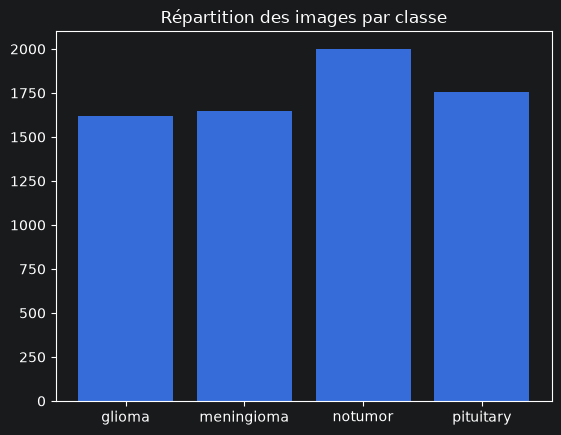

In [5]:
from data_utils import plot_class_distribution
plot_class_distribution("../Data/raw")

## Normalisation des pixels

On ramène les intensités de `[0, 255]` (uint8) vers `[0, 1]` (float32) en divisant par 255. Indispensable pour stabiliser et accélérer l'entraînement du réseau.

In [6]:
from data_utils import list_image_files, load_image, normalize

paths, _ = list_image_files("../Data/raw")
img = load_image(paths[0])                 # uint8, [0, 255]
img_norm, _ = normalize(img, 0)            # float32, [0, 1]

print("avant :", img.dtype, "min", int(img.min()), "max", int(img.max()),
      "moyenne", round(float(img.mean()), 2))
print("après :", img_norm.numpy().dtype, "min", float(img_norm.numpy().min()),
      "max", float(img_norm.numpy().max()),
      "moyenne", round(float(img_norm.numpy().mean()), 4))


avant : uint8 min 0 max 245 moyenne 30.45
après : float32 min 0.0 max 0.9607843160629272 moyenne 0.1194


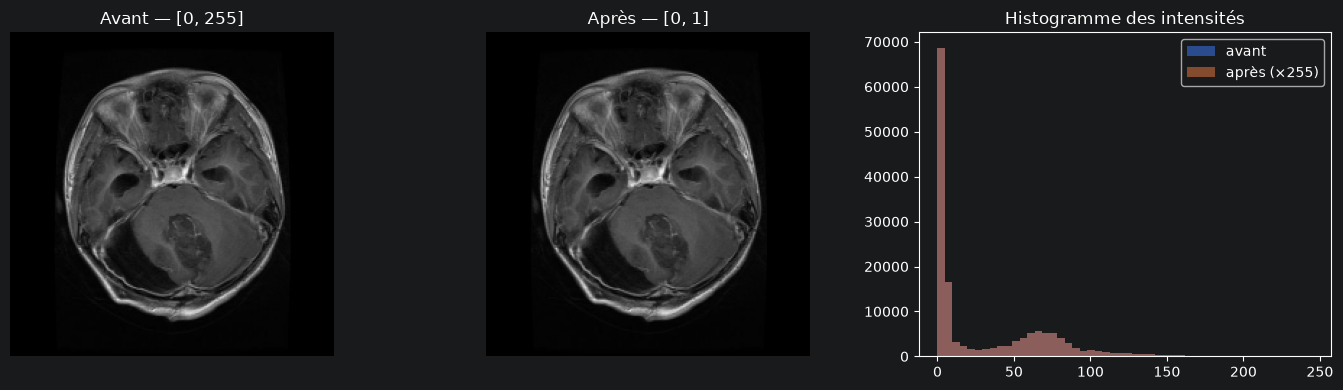

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(img)
axes[0].set_title("Avant — [0, 255]")
axes[1].imshow(img_norm.numpy())
axes[1].set_title("Après — [0, 1]")
axes[2].hist(img.ravel(), bins=50, alpha=0.6, label="avant")
axes[2].hist(img_norm.numpy().ravel() * 255, bins=50, alpha=0.6, label="après (×255)")
axes[2].set_title("Histogramme des intensités")
axes[2].legend()
axes[0].axis("off")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## Augmentation de données (adaptée IRM)



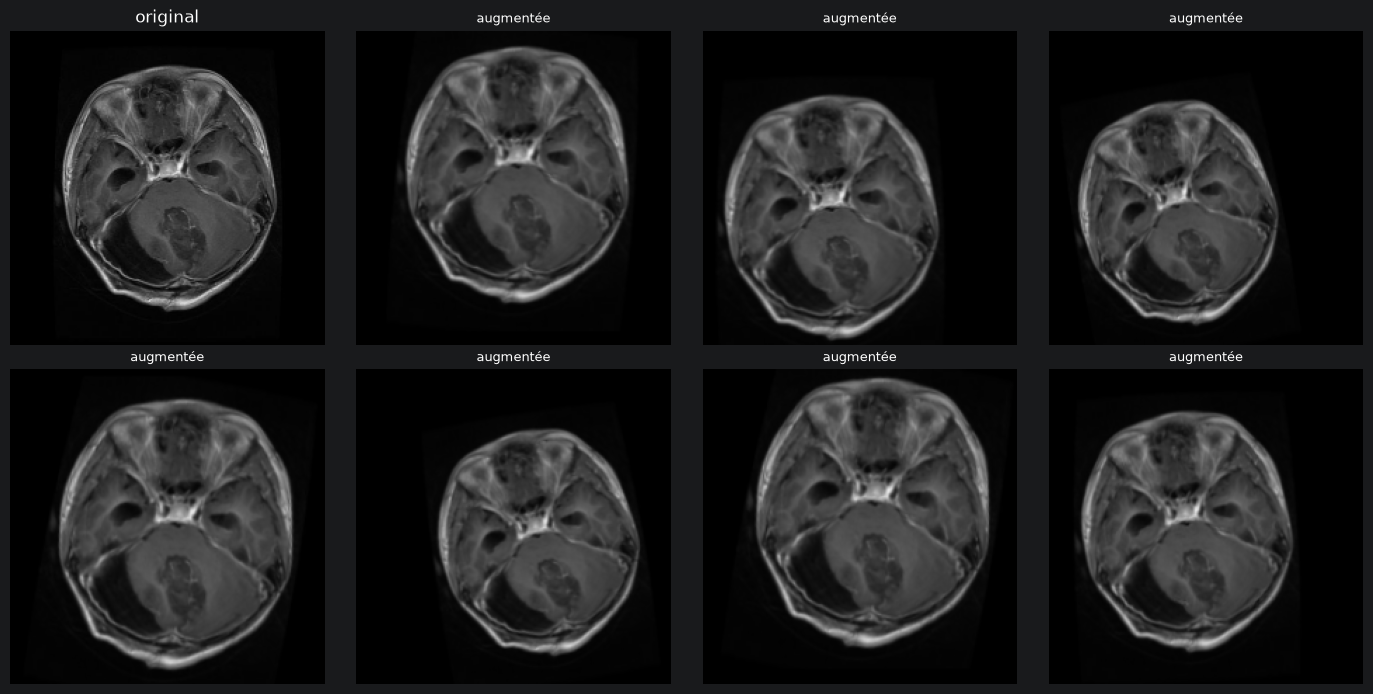

In [8]:
import numpy as np
from data_utils import make_augmentation

augment = make_augmentation(rotation=0.03, zoom=0.1, translation=0.1, seed=42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
axes[0].imshow(img_norm.numpy())
axes[0].set_title("original")
for ax in axes[1:]:
    aug = augment(img_norm[None, ...], training=True)[0].numpy()
    ax.imshow(np.clip(aug, 0, 1))
    ax.set_title("augmentée", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Division en ensembles d'entraînement / validation / test


In [9]:
import tensorflow as tf
from data_utils import CLASSES, list_image_files, split_paths, make_datasets

paths, labels = list_image_files("../Data/raw")
splits = split_paths(paths, labels, val_split=0.15, test_split=0.15, seed=42)
for name, (p, y) in splits.items():
    counts = np.bincount(y, minlength=len(CLASSES))
    print(f"{name:5s} {len(p):5d} images ->", dict(zip(CLASSES, counts)))


train  4916 images -> {'glioma': np.int64(1135), 'meningioma': np.int64(1151), 'notumor': np.int64(1400), 'pituitary': np.int64(1230)}
val    1053 images -> {'glioma': np.int64(243), 'meningioma': np.int64(247), 'notumor': np.int64(300), 'pituitary': np.int64(263)}
test   1054 images -> {'glioma': np.int64(243), 'meningioma': np.int64(247), 'notumor': np.int64(300), 'pituitary': np.int64(264)}


In [10]:
datasets, classes = make_datasets(
    "../Data/raw", batch_size=32, val_split=0.15, test_split=0.15,
    seed=42, normalize=True, augmentation=augment)

for name, ds in datasets.items():
    n = tf.data.experimental.cardinality(ds).numpy()
    print(f"{name:5s}: {n} lots de 32")

for name in ("train", "test"):
    images, _ = next(iter(datasets[name].take(1)))
    arr = images.numpy()
    print(f"{name:5s} -> {images.shape} {images.dtype} "
          f"min={arr.min():.3f} max={arr.max():.3f}")


train: 154 lots de 32
val  : 33 lots de 32
test : 33 lots de 32
train -> (32, 224, 224, 3) <dtype: 'float32'> min=0.000 max=0.998
test  -> (32, 224, 224, 3) <dtype: 'float32'> min=0.000 max=1.000


W0000 00:00:1792062108.111526   74773 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
W0000 00:00:1792062108.186664   74797 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
